In [ ]:
import os
import sys

# Проверяем, запущен ли ноутбук в среде Google Colab
if "google.colab" in sys.modules:
    !pip install uv -q
    !wget https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_7/pyproject.toml -q
    !uv pip install -r pyproject.toml --system -q
    os.kill(os.getpid(), 9)  # force runtime restart

# 2. Признаки из истории ряда: лаги и окна

Календарные признаки (ноутбук 1) описывают «типичный» день: каким бывает вторник в апреле.
Признаки из истории добавляют **текущее состояние** ряда: если последние недели продажи
выше обычного, то и через две недели они, скорее всего, будут выше.

Главное ограничение — из постановки: при прогнозе на `H` шагов можно использовать только
то, что известно на момент прогноза, то есть значения ряда не позже `t-H`.

1. Лаги: выбор по ACF/PACF, сезонные лаги, прямая и рекурсивная стратегии.
2. Окна: скользящие, сезонные и расширяющиеся статистики.

In [1]:
import common  # первым: глушит предупреждения ETNA при импорте

common.quiet()

from etna.analysis import acf_plot
from etna.models import LinearPerSegmentModel
from etna.pipeline import AutoRegressivePipeline
from etna.transforms import (
    FourierTransform,
    HolidayTransform,
    LagTransform,
    LinearTrendTransform,
    MeanTransform,
    QuantileTransform,
    StdTransform,
)

HORIZON = 14
# ряд с индикаторами 10 дней до Нового года из ноутбука 1
onion = common.load_onion(new_year_days=10)
calendar = [
    LinearTrendTransform(in_column="target"),
    *common.dow(),
    FourierTransform(period=365.25, order=3, out_column="f365"),
    HolidayTransform(iso_code="RUS", out_column="holiday"),
]

## 1. Лаговые признаки

Лаг `k` — это просто значение ряда `k` шагов назад: `y[t-k]`.

### Какие лаги брать: ACF и PACF

**ACF** — корреляция ряда с самим собой со сдвигом `k`. **PACF** — та же корреляция, но
очищенная от влияния промежуточных лагов: показывает, что лаг `k` добавляет сверх лагов
`1…k-1`. Пики на 7, 14, 21… — недельная сезонность; медленное затухание ACF — длинная
«память» уровня ряда.

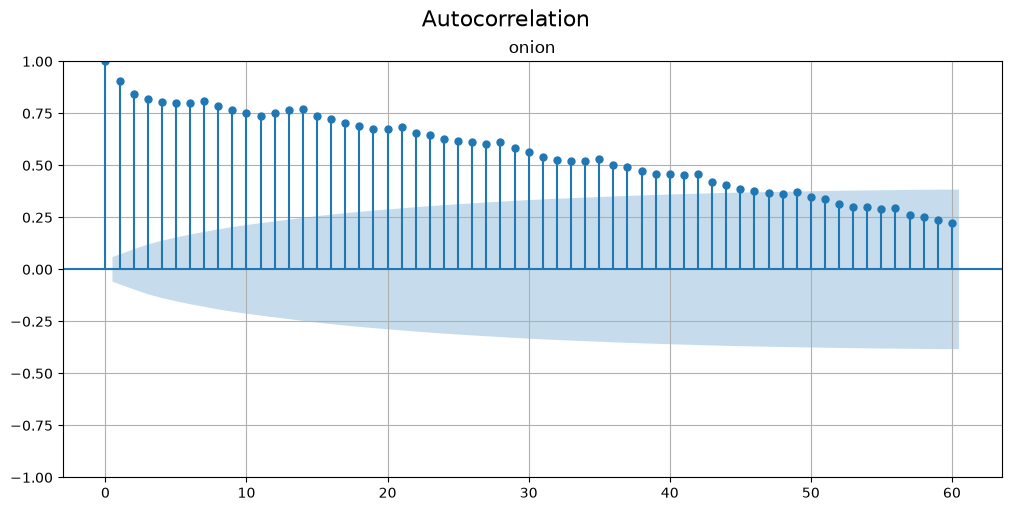

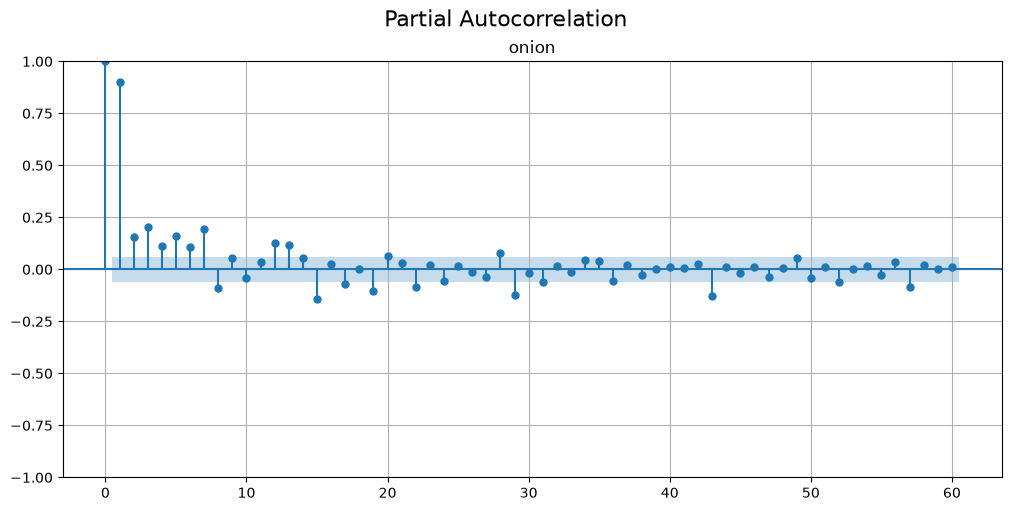

In [2]:
acf_plot(onion, lags=60)
acf_plot(onion, lags=60, partial=True)

Для прогноза на 14 дней нам доступны лаги начиная с 14. Сравним несколько наборов поверх
календарных признаков:
- один лаг 14;
- сплошной блок 14…20 (последняя доступная неделя целиком);
- сезонные лаги 14, 21, 28, 35 (тот же день недели) и 364 (тот же день недели год назад).

In [3]:
lag_sets = {
    "только календарь": [],
    "лаг 14": [14],
    "лаги 14…20": list(range(14, 21)),
    "лаги 14, 21, 28, 35, 364": [14, 21, 28, 35, 364],
}
results = {
    name: common.backtest(
        LinearPerSegmentModel(),
        calendar
        + ([LagTransform(in_column="target", lags=lags, out_column="lag")] if lags else []),
        onion,
        HORIZON,
    )
    for name, lags in lag_sets.items()
}
common.compare(results)

,WAPE,MAE
только календарь,0.0662,4458.7999
лаг 14,0.0622,4177.1858
лаги 14…20,0.0620,4187.5664
"лаги 14, 21, 28, 35, 364",0.0551,3727.9498


Лаги улучшают прогноз поверх календаря: модель подстраивается под текущий уровень спроса,
которого нет в календарных признаках. Сезонные лаги (кратные 7) работают лучше сплошного
блока: недельный рисунок у них совпадает с прогнозируемым днём.

### А если нужен лаг 1? Рекурсивная стратегия

Короткие лаги несут больше всего информации, но для дня `t+2` значение `y[t+1]` ещё
неизвестно. **Рекурсивная** стратегия подставляет вместо него собственный прогноз:
предсказали день 1 → используем его как лаг 1 для дня 2 → и так далее. В ETNA это
`AutoRegressivePipeline` (`step` — сколько шагов прогнозировать за раз).

Обычный `Pipeline` с лагами `≥ H` — **прямая** (direct) стратегия: одна модель сразу на
весь горизонт, без подстановки прогнозов.

In [4]:
results["рекурсивно, лаги 1, 2, 7, 14"] = AutoRegressivePipeline(
    LinearPerSegmentModel(),
    horizon=HORIZON,
    transforms=calendar + [LagTransform(in_column="target", lags=[1, 2, 7, 14], out_column="lag")],
    step=1,
).backtest(ts=onion, metrics=common.METRICS, n_folds=3, joblib_params=dict(verbose=0))
common.compare(results)

,WAPE,MAE
только календарь,0.0662,4458.7999
лаг 14,0.0622,4177.1858
лаги 14…20,0.0620,4187.5664
"лаги 14, 21, 28, 35, 364",0.0551,3727.9498
"рекурсивно, лаги 1, 2, 7, 14",0.0609,4047.4625


Рекурсия обыгрывает один лаг 14, но не сезонные лаги: свежие лаги полезны, однако ошибка
прогноза на первых шагах попадает в лаги следующих шагов и **накапливается** по горизонту.
Это типичный компромисс:

| Стратегия | Плюсы | Минусы |
|---|---|---|
| прямая (лаги `≥ H`) | ошибки не накапливаются, одна модель | теряем свежие лаги |
| рекурсивная (`AutoRegressivePipeline`) | используем самые свежие лаги | ошибки накапливаются, медленнее |

Лаги — способ сообщить линейной модели текущий уровень ряда. Выбирайте их по ACF/PACF и
сезонности (кратные периоду), начиная с горизонта.

## 2. Скользящие и расширяющиеся окна

Лаг — одна точка из прошлого, и она шумная. Статистика по **окну** точек (среднее, разброс,
квантиль) даёт более устойчивую оценку текущего уровня и волатильности ряда.

| Окно | Что считает | В ETNA |
|---|---|---|
| скользящее | статистика по последним `window` точкам | `MeanTransform(window=7)` |
| сезонное | по точкам с шагом `seasonality` (те же дни недели) | `MeanTransform(window=4, seasonality=7)` |
| расширяющееся | по всей истории до текущей точки | `MeanTransform(window=-1)` |

Есть и другие статистики: `StdTransform`, `QuantileTransform`, `MADTransform`,
`MinMaxDifferenceTransform`, `MedianTransform`, `SumTransform`. Взвешенных окон в ETNA нет —
при необходимости их считают вручную (7.1.1 §4).

### Ловушка: окно поверх `target`

Окно по `target` в момент `t` включает сам `y[t]` и ближайшие дни — на горизонте их нет.
ETNA знает об этом: модель обучается только на **регрессорах** (признаках, известных на весь
горизонт), а окно по `target` регрессором не считается. Модель молча его пропускает.

In [5]:
with_lag = calendar + [LagTransform(in_column="target", lags=[HORIZON], out_column="lag")]
ignored = common.backtest(
    LinearPerSegmentModel(),
    with_lag + [MeanTransform(in_column="target", window=7, out_column="mean7_target")],
    onion,
    HORIZON,
)
used = ignored["pipelines"][0].model._models["onion"].regressor_columns
print("mean7_target среди признаков модели:", "mean7_target" in used)

mean7_target среди признаков модели: False


Правильный способ — считать окно **поверх лага** `lag_14`. Тогда окно в момент `t` покрывает
дни `t-14 … t-20`: всё это известно на момент прогноза, и признак — регрессор.

### Сравнение окон

In [6]:
lag = f"lag_{HORIZON}"
windows = {
    "только лаг 14": [],
    "+ среднее за 7 дней": [MeanTransform(in_column=lag, window=7, out_column="mean7")],
    "+ средние за 7 и 28 дней": [
        MeanTransform(in_column=lag, window=7, out_column="mean7"),
        MeanTransform(in_column=lag, window=28, out_column="mean28"),
    ],
    "+ сезонное среднее (4 недели)": [
        MeanTransform(in_column=lag, window=4, seasonality=7, out_column="smean4")
    ],
    "+ расширяющееся среднее": [
        MeanTransform(in_column=lag, window=-1, out_column="expanding_mean")
    ],
    "+ std за 7 дней": [StdTransform(in_column=lag, window=7, out_column="std7")],
    "+ квантиль 0.9 за 28 дней": [
        QuantileTransform(in_column=lag, quantile=0.9, window=28, out_column="q90")
    ],
}
common.compare(
    {
        name: common.backtest(LinearPerSegmentModel(), with_lag + extra, onion, HORIZON)
        for name, extra in windows.items()
    }
)

,WAPE,MAE
только лаг 14,0.0622,4177.1858
+ среднее за 7 дней,0.0589,4001.2775
+ средние за 7 и 28 дней,0.0579,3890.7641
+ сезонное среднее (4 недели),0.0622,4209.6456
+ расширяющееся среднее,0.0630,4247.7803
+ std за 7 дней,0.0700,4730.7997
+ квантиль 0.9 за 28 дней,0.0632,4326.2246


- **Скользящие средние** помогают: короткое (7 дней) усредняет шум последней известной
  недели, длинное (28) добавляет «медленный» уровень. Вместе — лучше всего.
- **Сезонное** и **расширяющееся** средние здесь ничего не дают: недельный рисунок и
  долгий уровень уже описаны днём недели и трендом. Расширяющееся среднее полезно, когда
  тренда в признаках нет и нужна «средняя за всю историю».
- **Std и квантили** — признаки волатильности. Линейная модель прогнозирует среднее, и
  прямой пользы от разброса ей нет: здесь они только добавляют шум. Для деревьев и
  вероятностных моделей такие признаки полезнее.

Гиперпараметры окна: `window` (длина; `-1` — вся история), `seasonality` (шаг между точками),
`min_periods` (сколько точек нужно, чтобы посчитать значение в начале ряда), `fillna`
(чем заполнить, пока точек не хватает).

## Итог

Окно — это сглаженный лаг. Правила для лагов и окон одни и те же: считать только по
известным на горизонте данным (лаг `≥ H`, окно поверх такого лага) и проверять пользу
бэктестом. На луке: календарь 0.066 → сезонные лаги 0.055, или лаг 14 + средние за 7 и
28 дней 0.058.

Признаков становится много — что с этим делать и как работать сразу с многими рядами,
разберём в ноутбуке 3.